In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import openpyxl
from scipy.stats import norm

In [13]:
# BẢNG SỐ LIỆU FIT VỪA KHUNG CODE / NOTEBOOK – KHÔNG CẦN CUỘN TRONG BẢNG
# Chỉ thay đổi cách trình bày, không thay dữ liệu, công thức hay các biểu đồ.
from IPython.display import HTML, display
from html import escape
import pandas as pd


def hien_thi_bang(du_lieu, tieu_de, ghi_chu="", dinh_dang=None, chieu_cao=None):
    """Bảng tự co vừa khung notebook, không có thanh cuộn dọc/ngang riêng.

    chieu_cao giữ lại để tương thích các lệnh gọi cũ, nhưng không còn giới hạn
    chiều cao bảng: toàn bộ hàng được hiển thị ngay dưới cell code.
    """
    bang = du_lieu.copy().reset_index(drop=True)
    dinh_dang = dinh_dang or {}
    so_cot = len(bang.columns)
    if so_cot == 0:
        display(HTML("<p>Không có cột dữ liệu để hiển thị.</p>"))
        return

    def dinh_dang_o(gia_tri, ten_cot):
        if pd.isna(gia_tri):
            return "—"
        mau = dinh_dang.get(ten_cot)
        if mau:
            try:
                return str(mau.format(gia_tri))
            except (ValueError, TypeError):
                pass
        return str(gia_tri)

    # Giữ nội dung trong phạm vi độ rộng ô Output. Không set min-width, không overflow:auto.
    css = """
      <style>
      .bang-fit-wrap {box-sizing:border-box!important;width:100%!important;max-width:100%!important;
         margin:12px 0 20px;padding:12px 12px 8px;border:1px solid #dce5ef;
         border-radius:10px;background:#fff;color:#1b354f;font-family:Arial,sans-serif;
         overflow:visible!important;}
      .bang-fit-top {display:flex;align-items:center;justify-content:space-between;
         flex-wrap:wrap;gap:7px;margin-bottom:7px;}
      .bang-fit-title {font-size:16px;font-weight:700;line-height:1.4;min-width:0;}
      .bang-fit-count {font-size:12px;font-weight:600;white-space:nowrap;
         color:#096d74;background:#e2f4f4;border-radius:20px;padding:4px 9px;}
      .bang-fit-note {font-size:12px;line-height:1.5;color:#516983;
         margin-bottom:9px;overflow-wrap:anywhere;}
      table.bang-fit-table {border-collapse:collapse!important;border-spacing:0!important;
         table-layout:fixed!important;width:100%!important;max-width:100%!important;
         min-width:0!important;margin:0!important;font-family:Arial,sans-serif;
         font-size:13px!important;border:1px solid #cfdeeb;}
      table.bang-fit-table thead th {box-sizing:border-box!important;text-align:center!important;
         padding:9px 5px!important;background:#173f69!important;color:#fff!important;
         font-weight:700!important;line-height:1.35!important;
         border:1px solid #3e668e!important;white-space:normal!important;
         overflow-wrap:break-word!important;word-break:normal!important;}
      table.bang-fit-table tbody td {box-sizing:border-box!important;text-align:center!important;
         padding:6px 4px!important;line-height:1.35!important;
         color:#203a55!important;border:1px solid #dfe8f0!important;
         font-variant-numeric:tabular-nums!important;white-space:normal!important;
         overflow-wrap:anywhere!important;}
      table.bang-fit-table tbody tr:nth-child(even) td {background:#f0f6fb!important;}
      table.bang-fit-table tbody tr:nth-child(odd) td {background:#fff!important;}
      table.bang-fit-table tbody tr:hover td {background:#dbf3ed!important;}
      @media (max-width: 650px) {
         .bang-fit-wrap {padding:8px 5px 5px!important;}
         .bang-fit-title {font-size:14px!important;}
         .bang-fit-note {font-size:11px!important;}
         table.bang-fit-table {font-size:11px!important;}
         table.bang-fit-table thead th {padding:7px 2px!important;}
         table.bang-fit-table tbody td {padding:5px 2px!important;}
      }
      </style>
    """
    widths = (["18%", "82%"] if so_cot == 2 else
              ["17%", "28%", "27%", "28%"] if so_cot == 4 else
              [f"{100 / so_cot:.4f}%"] * so_cot)
    headers = "".join(f'<th scope="col" style="width:{widths[i]}">{escape(str(col))}</th>'
                      for i, col in enumerate(bang.columns))
    rows = []
    for k, values in enumerate(bang.itertuples(index=False, name=None)):
        cells = "".join(
            f'<td>{escape(dinh_dang_o(value, col))}</td>'
            for col, value in zip(bang.columns, values)
        )
        rows.append(f'<tr>{cells}</tr>')
    note = f'<div class="bang-fit-note">{escape(ghi_chu)}</div>' if ghi_chu else ""
    output = (
        css + '<div class="bang-fit-wrap">'
        + '<div class="bang-fit-top">'
        + f'<div class="bang-fit-title">{escape(tieu_de)}</div>'
        + f'<span class="bang-fit-count">{len(bang)} quan sát</span>'
        + '</div>' + note
        + '<table class="bang-fit-table"><colgroup>'
        + "".join(f'<col style="width:{x}">' for x in widths)
        + '</colgroup><thead><tr>' + headers + '</tr></thead><tbody>'
        + "".join(rows)
        + '</tbody></table>'
        + '</div>'
    )
    display(HTML(output))


def hien_thi_bang_qq(bang_qq, tieu_de, so_le_x=2):
    """Bảng Q–Q bốn cột gọn; giải thích ký hiệu ở dòng ghi chú phía trên."""
    bang_ro = bang_qq.rename(columns={
        "j": "STT (j)",
        "x_j": "Giá trị (xⱼ)",
        "(j - 0,5)/n": "Xác suất (pⱼ)",
        "z_j = Φ⁻¹((j - 0,5)/n)": "Phân vị (zⱼ)",
    })
    hien_thi_bang(
        bang_ro,
        tieu_de=tieu_de,
        ghi_chu="xⱼ: số liệu tăng dần; pⱼ = (j − 0,5)/n; zⱼ = Φ⁻¹(pⱼ). Bảng tự vừa khung, hiển thị đủ tất cả các hàng.",
        dinh_dang={
            "STT (j)": "{:.0f}",
            "Giá trị (xⱼ)": "{:." + str(so_le_x) + "f}",
            "Xác suất (pⱼ)": "{:.3f}",
            "Phân vị (zⱼ)": "{:+.3f}",
        },
    )


In [14]:
data = pd.read_excel('Data/Database_no_chuan.xlsx', skiprows = 1, header = None)
array_data = data.to_numpy().ravel()
array_data = array_data[pd.notna(array_data)]
hien_thi_bang(
    pd.DataFrame({'STT': np.arange(1, len(array_data) + 1), 'Giá trị': array_data}),
    'DỮ LIỆU GỐC – MẪU KHÔNG PHÂN PHỐI CHUẨN',
    ghi_chu='Dữ liệu theo thứ tự đọc từ Database_no_chuan.xlsx.',
    dinh_dang={'STT': '{:.0f}', 'Giá trị': '{:.2f}'},
    chieu_cao=360
)

STT,Giá trị
1,1.23
2,0.49
3,0.49
4,1.08
5,0.59
6,0.28
7,0.18
8,0.10
9,0.94
10,1.33


STT (j),Giá trị (xⱼ),Xác suất (pⱼ),Phân vị (zⱼ)
1,0.04,0.009,-2.348
2,0.04,0.028,-1.906
3,0.04,0.047,-1.673
4,0.05,0.066,-1.506
5,0.10,0.085,-1.373
6,0.15,0.104,-1.260
7,0.16,0.123,-1.162
8,0.17,0.142,-1.074
9,0.18,0.160,-0.993
10,0.19,0.179,-0.918


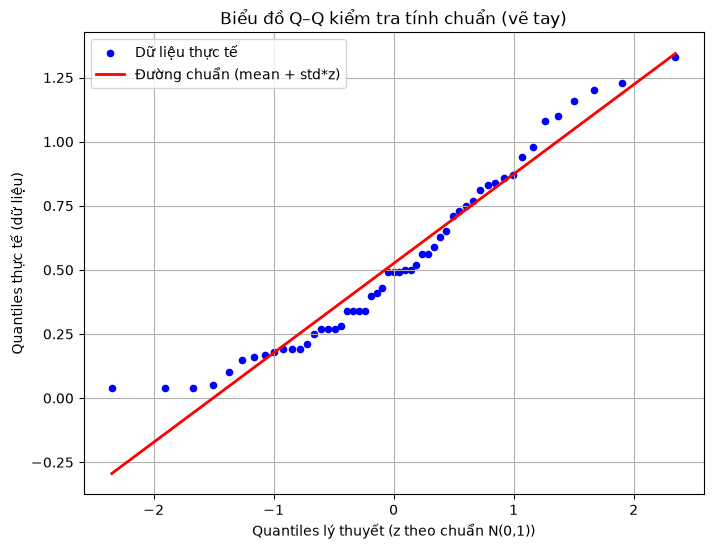

In [16]:
import scipy.stats as stats
n = len(df)
p = (np.arange(1, n + 1) - 0.5) / n
z_j = stats.norm.ppf(p)     # giá trị z lý thuyết
q_thuc = df          
line_x = np.linspace(min(z_j), max(z_j), 100)
line_y = mean + std * line_x

# BẢNG SỐ LIỆU TRƯỚC BIỂU ĐỒ Q-Q (giống bảng trong giáo trình)
bang_qq = pd.DataFrame({
    'j': np.arange(1, n + 1),
    'x_j': df['Giá trị'].to_numpy(dtype=float),
    '(j - 0,5)/n': p,
    'z_j = Φ⁻¹((j - 0,5)/n)': z_j
})
hien_thi_bang_qq(bang_qq, f'BẢNG PHÂN VỊ CHUẨN – MẪU KHÔNG CHUẨN (n = {n})')

# Vẽ biểu đồ
plt.figure(figsize=(8, 6))
plt.scatter(z_j, q_thuc, color='blue', s=20, label='Dữ liệu thực tế')
plt.plot(line_x, line_y, color='red', linewidth=2, label='Đường chuẩn (mean + std*z)')

plt.title('Biểu đồ Q–Q kiểm tra tính chuẩn (vẽ tay)')
plt.xlabel('Quantiles lý thuyết (z theo chuẩn N(0,1))')
plt.ylabel('Quantiles thực tế (dữ liệu)')
plt.legend()
plt.grid(True)
plt.show()


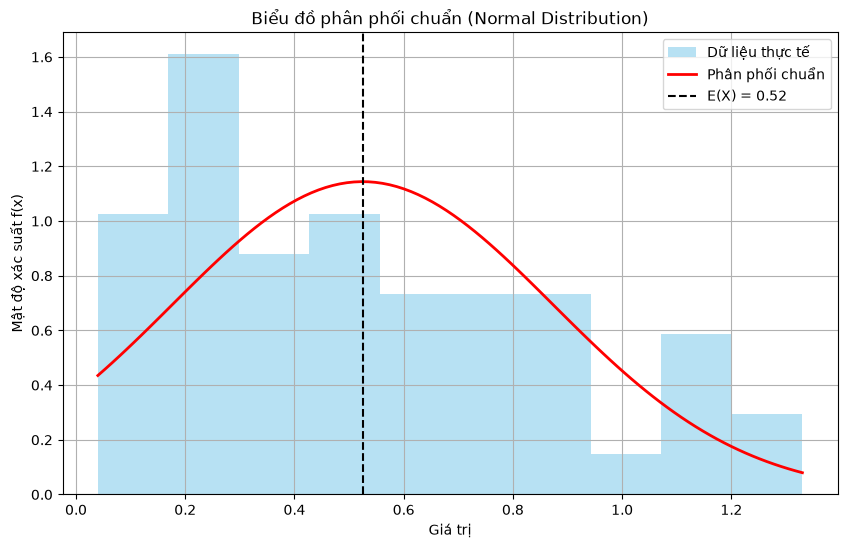

In [17]:
# Vẽ biểu đồ histogram 
plt.figure(figsize=(10, 6))
plt.hist(df['Giá trị'], bins=10, density=True, alpha=0.6, color='skyblue', label='Dữ liệu thực tế')

# Vẽ đường cong phân phối chuẩn
x = np.linspace(df['Giá trị'].min(), df['Giá trị'].max(), 100)
y = norm.pdf(x, mean, std)
plt.plot(x, y, color='red', linewidth=2, label='Phân phối chuẩn')

# Vẽ đường thẳng trung bình
plt.axvline(mean, color='black', linestyle='--', label=f'E(X) = {mean:.2f}')

# Thêm tiêu đề và nhãn
plt.title('Biểu đồ phân phối chuẩn (Normal Distribution)')
plt.xlabel('Giá trị')
plt.ylabel('Mật độ xác suất f(x)')
plt.legend()
plt.grid(True)
plt.show()